# 3. Model Building

What the brief asks for, and where each part is answered:

| Brief | Section |
|---|---|
| Predict `target_default` using engineered features (aggregate bureau + repayment history, not just raw application fields) | 3.0, 3.2 |
| Baseline (logistic regression) + one ML model (XGBoost / LightGBM) | 3.1 |
| Report AUC, KS, Gini + feature importance / SHAP | 3.1, 3.2 |
| One paragraph: how you'd monitor this model post-deployment (PSI/CSI, retraining cadence) | 3.4 |

Training code: `src/train_model.py`; features and explanations: `src/features.py`. This notebook reads the saved results
in `reports/` and the saved models in `models/`.

## 3.0 Features and validation

**Engineered features** combine the application (income, job tenure, loan size, affordability ratios), the customer's
**bureau history aggregated to one row per customer** (active lines, write-offs, days past due, debt-to-income, lender
mix) and the account's **first 12 months of repayment aggregated to one row per account** (late and missed counts,
worst days past due, recent misses). No account reaches 90 days past due inside that window, so the repayment features
describe behaviour *before* default and don't leak the target.

**Validation:** (1) a hold-out test set of 20% of *customers*, so shared bureau data can't leak between train and test;
(2) 5-fold cross-validation grouped by customer, used to tune both models; (3) an out-of-time check, training on
2018–2021 originations and testing on 2022–2023 loans of new customers. **Champion rule:** LightGBM must beat the
logistic regression by at least 0.01 test AUC to justify a less transparent model.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib.pyplot as plt
from nbstyle import BLUE, ORANGE, STATUS, rate_barh, paired_barh, heatmap
import portfolio as pf
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
book = pf.load_book()

from pathlib import Path
import joblib
from evaluation import ks_statistic
from features import LABELS, EXPECTED_SIGN, logistic_term, model_frame, contributions
REPORTS = Path("../reports")
metrics = json.loads((REPORTS / "model_metrics.json").read_text())
test = pd.read_csv(REPORTS / "test_predictions.csv")

## 3.1 Baseline (logistic regression) vs ML model (LightGBM): AUC, KS, Gini

In [2]:
names = {"logistic": "Logistic regression (baseline)", "lightgbm": "LightGBM (ML model)"}
rows = {}
for kind, m in metrics["models"].items():
    rows[names[kind]] = {"CV AUC (mean)": m["cv_auc_mean"], "CV AUC (sd)": m["cv_auc_std"],
                         "Test AUC": m["test"]["auc"], "Test Gini": m["test"]["gini"], "Test KS": m["test"]["ks"],
                         "Brier": m["test"]["brier"], "Out-of-time AUC": m["out_of_time"]["auc"],
                         "Train AUC": m["train"]["auc"]}
print(f"Champion: {metrics['champion']} (LightGBM test AUC gain {metrics['lightgbm_auc_gain_on_test']:+.3f},"
      f" needed >= {metrics['materiality_auc']})")
pd.DataFrame(rows).T.style.format("{:.3f}")

Champion: logistic (LightGBM test AUC gain -0.009, needed >= 0.01)


,CV AUC (mean),CV AUC (sd),Test AUC,Test Gini,Test KS,Brier,Out-of-time AUC,Train AUC
Logistic regression (baseline),0.672,0.007,0.687,0.375,0.288,0.125,0.700,0.685
LightGBM (ML model),0.668,0.005,0.678,0.356,0.277,0.126,0.695,0.763


**The logistic regression baseline is the champion.** LightGBM (tuned, with monotone constraints) scored 0.009 *lower*
on the test set and overfits (train AUC 0.763 vs test 0.678). The signal in this data is mostly additive and monotonic,
which a linear model captures fully. For a bank this is the better outcome: the scorecard is transparent, its
explanations are exact, and it supports adverse-action reason codes.

An AUC around 0.69 (Gini 0.37, KS 0.29) is the honest ceiling here: the initial audit found no feature combination
above about 0.70. Scores far above that would point to leakage, not skill.

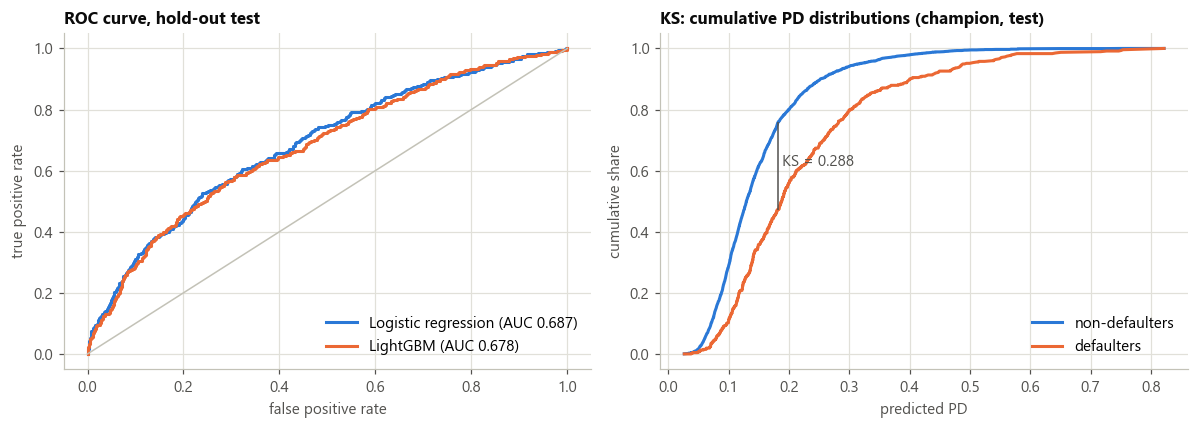

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
from sklearn.metrics import roc_curve
for col, name, color in [("pd_logistic", "Logistic regression", BLUE), ("pd_lightgbm", "LightGBM", ORANGE)]:
    fpr, tpr, _ = roc_curve(test.target_default, test[col])
    left.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {metrics['models'][col[3:]]['test']['auc']:.3f})")
left.plot([0, 1], [0, 1], color="#c3c2b7", lw=1)
left.set(title="ROC curve, hold-out test", xlabel="false positive rate", ylabel="true positive rate")
left.legend(loc="lower right")

p, y = test.pd, test.target_default
grid = sorted(p.unique())
cdf_bad = [((p[y == 1]) <= g).mean() for g in grid]
cdf_good = [((p[y == 0]) <= g).mean() for g in grid]
gap = [g - b for g, b in zip(cdf_good, cdf_bad)]
k = max(range(len(gap)), key=gap.__getitem__)
right.plot(grid, cdf_good, color=BLUE, lw=2, label="non-defaulters")
right.plot(grid, cdf_bad, color=ORANGE, lw=2, label="defaulters")
right.vlines(grid[k], cdf_bad[k], cdf_good[k], color="#52514e", lw=1)
right.annotate(f" KS = {ks_statistic(y, p):.3f}", (grid[k], (cdf_bad[k] + cdf_good[k]) / 2), color="#52514e")
right.set(title="KS: cumulative PD distributions (champion, test)", xlabel="predicted PD", ylabel="cumulative share")
right.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [4]:
deciles = pd.read_csv(REPORTS / "deciles_test.csv")
bands = pd.read_csv(REPORTS / "risk_bands_test.csv")
display(deciles.style.format({c: "{:.1%}" for c in ["default_rate", "avg_pd", "min_pd", "max_pd", "share_of_defaults",
                                                    "cumulative_share_of_defaults"]} | {"lift": "{:.2f}x"}))
bands.style.format({"avg_predicted_pd": "{:.1%}", "actual_default_rate": "{:.1%}"})

,decile,accounts,defaults,default_rate,avg_pd,min_pd,max_pd,share_of_defaults,cumulative_share_of_defaults,lift
0,1,295,114,38.6%,38.7%,28.2%,82.2%,24.2%,24.2%,2.41x
1,2,295,73,24.7%,24.4%,21.5%,28.2%,15.5%,39.6%,1.55x
2,3,295,66,22.4%,19.6%,17.9%,21.5%,14.0%,53.6%,1.40x
3,4,294,41,13.9%,16.8%,15.7%,17.9%,8.7%,62.3%,0.87x
4,5,295,43,14.6%,14.5%,13.6%,15.7%,9.1%,71.4%,0.91x
5,6,295,37,12.5%,12.8%,12.0%,13.6%,7.8%,79.2%,0.78x
6,7,294,35,11.9%,11.3%,10.5%,12.0%,7.4%,86.7%,0.74x
7,8,295,22,7.5%,9.8%,9.1%,10.5%,4.7%,91.3%,0.47x
8,9,295,24,8.1%,8.2%,7.3%,9.1%,5.1%,96.4%,0.51x
9,10,295,17,5.8%,6.0%,2.6%,7.3%,3.6%,100.0%,0.36x


,risk_band,accounts,avg_predicted_pd,actual_default_rate
0,Low,769,7.7%,6.8%
1,Medium,1476,14.2%,14.4%
2,High,548,25.4%,26.1%
3,Very High,155,45.5%,41.9%


The riskiest 10% of accounts default at 38.6% (2.4x the average) and the riskiest 30% hold 54% of all defaults.
Predicted and actual default rates agree within each risk band (e.g. Very High: 45.5% predicted vs 41.9% actual), so
the PDs can be used as probabilities, not only as a ranking.

## 3.2 Feature importance and SHAP

The logistic scorecard uses one feature per idea, each with an expected direction. Training drops any feature whose
coefficient points the wrong way, which signals overlap with another feature and would make explanations misleading.

In [5]:
lf = metrics["logistic_features"]
print("Dropped by the sign check:", ", ".join(lf["dropped_by_sign_check"]))
print("Left out as near-duplicates:", ", ".join(lf["left_out_as_duplicates"]))
coef = pd.read_csv(REPORTS / "logistic_coefficients.csv").set_index("term").coefficient
pd.DataFrame([{"feature": LABELS[f], "expected direction": "raises risk" if EXPECTED_SIGN[f] > 0 else "lowers risk",
               "coefficient (standardised)": coef[logistic_term(f)]} for f in lf["numeric"]]
             ).sort_values("coefficient (standardised)", key=abs, ascending=False).style.format(
    {"coefficient (standardised)": "{:+.3f}"})

Dropped by the sign check: bureau_active_utilization, bureau_no_file, rep_months_since_missed, rep_max_missed_streak
Left out as near-duplicates: loan_amount, tenure_months, emi_to_income, bureau_n_lines, bureau_written_off_share, bureau_max_dpd, bureau_total_outstanding, rep_mean_dpd, rep_mean_dpd_last3, rep_paid_ratio, rep_dpd_trend


,feature,expected direction,coefficient (standardised)
13,Late payments (12 months),raises risk,+0.212
0,Annual income,lowers risk,-0.198
4,Loan / annual income,raises risk,+0.193
1,Years in current job,lowers risk,-0.189
14,Missed payments (12 months),raises risk,+0.172
7,Bureau: active lines,lowers risk,-0.150
9,Bureau: average days past due,raises risk,+0.118
10,Bureau: lines 30+ days late,raises risk,+0.105
5,Interest rate,raises risk,+0.087
2,Years at current address,lowers risk,-0.049


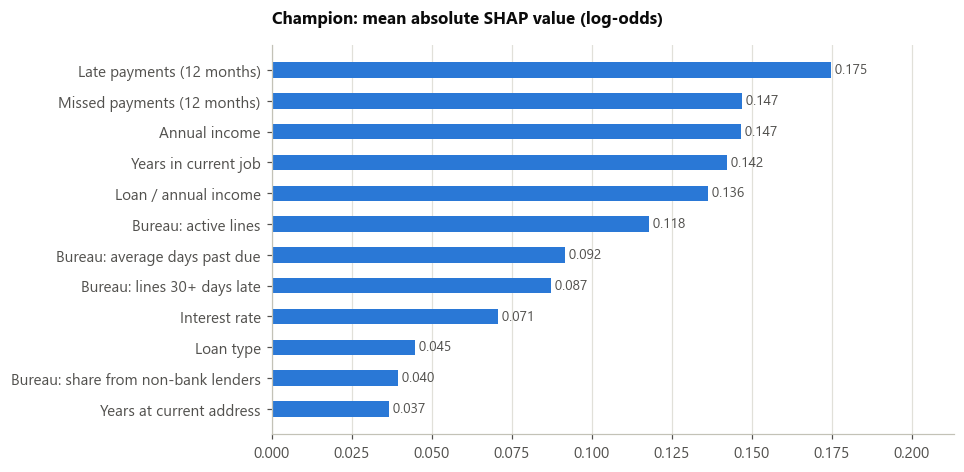

In [6]:
importance = pd.read_csv(REPORTS / "feature_importance.csv").dropna(subset=["mean_abs_shap_logistic"]).head(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
rate_barh(ax, importance.label, importance.mean_abs_shap_logistic, fmt="{:.3f}",
          title="Champion: mean absolute SHAP value (log-odds)")
plt.show()

For a logistic regression the SHAP value of a feature is exactly coefficient x (value − average value), so the
per-account drivers shown in the dashboard are exact, not approximations. Below, the LightGBM model's TreeSHAP values
tell the same story: late and missed payments, income, job tenure and loan-to-income lead.

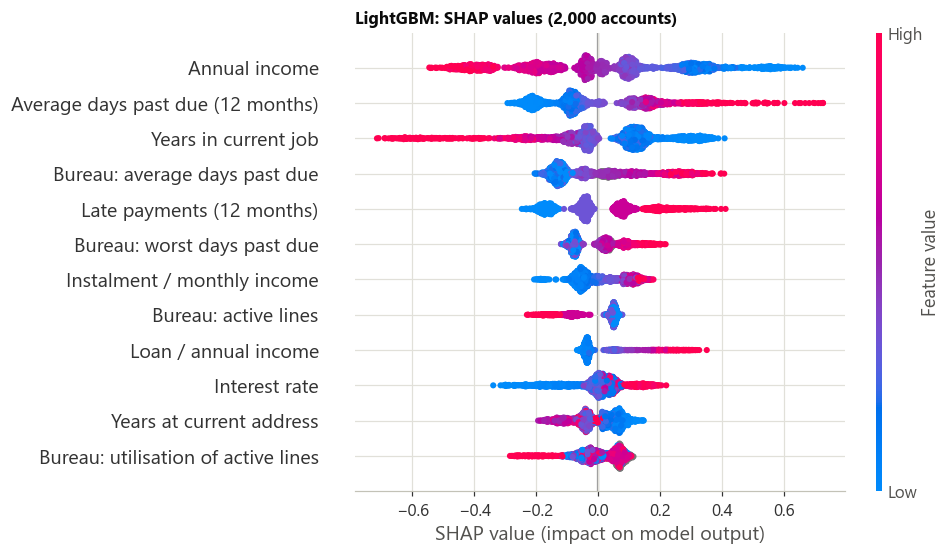

In [7]:
import shap
bundle = joblib.load("../models/lightgbm.joblib")
X = model_frame(book, bundle["categories"])
sample = X.sample(2000, random_state=42)
values = contributions(bundle, sample)
numeric = sample.copy()
for col in numeric.select_dtypes("category"):
    numeric[col] = numeric[col].cat.codes
shap.summary_plot(values.to_numpy(), numeric, feature_names=[LABELS[c] for c in sample.columns], max_display=12,
                  show=False, plot_size=(9, 5))
plt.title("LightGBM: SHAP values (2,000 accounts)")
plt.show()

## 3.3 Fairness

Gender, marital status and age are **not** model inputs. Age was taken out after testing, and training re-runs that test every time (`design_checks` in `src/train_model.py`): putting age back in barely changes test AUC but pushes the adverse impact ratio for 21–25 year-olds on the test set much further below the four-fifths line (numbers below). The remaining gap for young borrowers comes through income and job tenure, which are legitimate credit factors; it is documented for Compliance review rather than hidden.

In [8]:
checks = metrics["design_checks"]
age = checks["age"]
print(f"Test AUC without age {age['test_auc_without']:.3f} | with age {age['test_auc_with']:.3f}")
display(pd.DataFrame({"adverse impact ratio, without age": age["adverse_impact_ratio_test_without"],
                      "with age": age["adverse_impact_ratio_test_with"]}).rename_axis("age band (test set)"))
coll = checks["collections"]
print(f"Collections re-tested as inputs: test AUC {coll['test_auc_without']:.4f} without, "
      f"{coll['test_auc_with']:.4f} with ({', '.join(coll['features'])}): no lift, so they stay out")

fair = pd.read_csv(REPORTS / "fairness.csv")
fair["four-fifths test"] = fair.adverse_impact_ratio.map(lambda r: "pass" if r >= 0.8 else "review")
fair.style.format({"actual_default_rate": "{:.1%}", "avg_predicted_pd": "{:.1%}", "share_high_risk": "{:.1%}",
                   "adverse_impact_ratio": "{:.3f}"})

Test AUC without age 0.687 | with age 0.685


,"adverse impact ratio, without age",with age
age band (test set),,
21-25,0.729,0.528
26-35,0.824,0.716
36-45,0.881,0.847
46-55,0.921,0.930
56+,1.000,1.000


Collections re-tested as inputs: test AUC 0.6873 without, 0.6868 with (coll_n_events, coll_n_events_raw, coll_total_recovered): no lift, so they stay out


,group,attribute,accounts,actual_default_rate,avg_predicted_pd,share_high_risk,adverse_impact_ratio,four-fifths test
0,Female,gender,6296,16.3%,16.3%,24.1%,0.994,pass
1,Male,gender,8389,16.0%,16.0%,23.7%,1.000,pass
2,Divorced,marital_status,1403,17.0%,16.4%,25.1%,0.973,pass
3,Married,marital_status,8059,15.8%,16.1%,24.0%,0.988,pass
4,Single,marital_status,4472,16.6%,16.0%,23.4%,0.995,pass
5,Widowed,marital_status,751,14.6%,15.9%,23.0%,1.000,pass
6,21-25,age_band,1927,22.2%,19.4%,36.0%,0.716,review
7,26-35,age_band,4070,18.5%,17.5%,28.9%,0.796,review
8,36-45,age_band,5097,15.2%,15.4%,21.4%,0.880,pass
9,46-55,age_band,2758,11.7%,14.2%,16.5%,0.935,pass


## 3.4 Monitoring post-deployment (one paragraph)

After go-live the model would be monitored on three clocks. **Monthly**, the population stability index (PSI) of the
score distribution and the characteristic stability index (CSI) of the top ten features are compared with the
development baseline below: under 0.10 is stable, 0.10–0.25 triggers an investigation, and above 0.25 escalates to
model risk management. **Quarterly**, once enough outcomes have matured, AUC, KS and calibration by risk band are
re-measured against the validated baseline (test AUC 0.687, KS 0.288); a relative Gini drop of more than 10%, or a
gap of more than 20% between predicted and actual default rates in any band, triggers a review. The model is
**retrained annually**, or earlier on any breach, with LightGBM re-run as a challenger each time. Fairness ratios and
the AI feature's review outcomes are re-checked quarterly, and every change goes through independent validation in line
with SR 11-7.

In [9]:
champ = metrics["models"][metrics["champion"]]
print(f"Score PSI, train vs test: {champ['psi_train_vs_test']:.4f}")
print(f"Score PSI, 2018-21 vs 2022-23 vintages: {champ['psi_development_vs_recent']:.4f}")
pd.read_csv(REPORTS / "csi_baseline.csv").style.format({"csi_development_vs_recent": "{:.4f}"})

Score PSI, train vs test: 0.0028
Score PSI, 2018-21 vs 2022-23 vintages: 0.0072


,feature,label,csi_development_vs_recent,status
0,rep_n_late,Late payments (12 months),0.0007,Stable
1,rep_n_missed,Missed payments (12 months),0.0010,Stable
2,annual_income,Annual income,0.0009,Stable
3,years_employed,Years in current job,0.0017,Stable
4,loan_to_income,Loan / annual income,0.0016,Stable
5,bureau_n_active,Bureau: active lines,0.0001,Stable
6,bureau_mean_dpd,Bureau: average days past due,0.0009,Stable
7,bureau_n_dpd_30_plus,Bureau: lines 30+ days late,0.0001,Stable
8,interest_rate_pct,Interest rate,0.0022,Stable
9,loan_type,Loan type,0.0001,Stable


All baselines are far below 0.10: the synthetic data shows no drift between vintages. Real portfolios drift (rate
cycles, product changes, new channels), which is exactly what these checks exist to catch.